- **One fitted gate (`m`).** The model current is `g_bar * (V - e_r) * m`; all `h`-gate state and parameters are removed.
- **All 10 segments fitted together.** One shared `e_r` and `g_bar`; segments at the same voltage share `tau_m` and `m_inf`.
- **Gate state carries across segments**, starting at the holding-voltage steady state.
- **Whole-trace model uses fitted curves.** `m_inf` is a voltage sigmoid and `tau_m` is a voltage Gaussian.
- **The segment curves seed the first whole-trace fit.** Other starts are randomized with fixed seed.
- **Bounds are applied** to segment fits and whole-trace fits.
- **Best start is refitted** with up to 200 evaluations.

In [16]:
# %% SECTION 1: Packages import
import os
import numpy as np

# Import other packages as necessary
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

In [17]:
# %% SECTION 2: Helper functions
# Define functions if needed
# Bounds: [e_r, g_bar, m_inf steepness, m_inf center, tau_m scale, center, width]
lower = np.array([-150, 0, 0, -150, 0.01, -200, 1])
upper = np.array([150, 100, 1, 150, 1e3, 200, 1e5])
rng = np.random.default_rng(0)   # fixed seed -> reproducible
n_starts = 20

def gate_model(tau, x_0,x_inf,dt):
    y = x_0 + (x_inf - x_0) * (1 - np.exp(-dt / tau))
    return y

# Per-segment model: one voltage segment, with m carried between segments.
def get_current_segment(e_r, g_bar, tau_m, m_inf, v, t, m_0):
    m = np.zeros(len(v))
    m[0] = m_0

    for i in range(1, len(t)):
        dt = t[i] - t[i-1]
        m[i] = gate_model(tau_m, m[i-1], m_inf, dt)

    return g_bar * (v - e_r) * m, m[-1]

# [tau_m, m_inf] at step voltage number k.
def segment_params(params, k):
    return params[2+2*k:4+2*k]

# All 10 segments are fitted together, with one shared e_r and g_bar.
# Segments at the same voltage share gate parameters.
def compute_error_segment(params, data, past, seg_v, k_hold):
    e_r, g_bar = params[:2]
    _, m_0 = segment_params(params, k_hold)
    errors = []
    for j in range(1, 11):
        start = j*100-past
        stop = (j+1)*100
        tau_m, m_inf = segment_params(params, seg_v[j-1])
        current, m_0 = get_current_segment(e_r, g_bar, tau_m, m_inf, data[start:stop, 1], data[start:stop, 0], m_0)
        errors.append(current - data[start:stop, 2])
    return np.concatenate(errors)

# Whole-trace model: m_inf is a sigmoid and tau_m is a Gaussian of voltage.
def get_current(e_r, g_bar, m_params, tau_m_params, v, t):
    m = np.zeros(len(v))
    m_inf = sigmoid(*m_params, v)
    tau_m = np.maximum(gaussian(*tau_m_params, v), 1e-3)

    m[0] = m_inf[0]   # the trace starts at the holding voltage

    for i in range(1, len(t)):
        dt = t[i] - t[i-1]
        m[i] = gate_model(tau_m[i], m[i-1], m_inf[i], dt)

    return g_bar * (v - e_r) * m

def compute_error(params, t, v, test_i):
    e_r, g_bar = params[:2]
    return get_current(e_r, g_bar, params[2:4], params[4:7], v, t) - test_i

def random_start():
    e_r = rng.uniform(-100, 50)
    g_bar = 10 ** rng.uniform(-3, 0)    # log-uniform: spans orders of magnitude
    m_inf = [10 ** rng.uniform(-2, -0.5), rng.uniform(-80, 20)]
    tau_m = [10 ** rng.uniform(-1, 1), rng.uniform(-80, 20), 10 ** rng.uniform(2, 4)]
    return [e_r, g_bar, *m_inf, *tau_m]

def gaussian(scale, center, width, v):
    return scale * np.exp(-((v-center)**2) / width)

def compute_error_tau(params, v, tau):
    scale, center, width = params
    return gaussian(scale, center, width, v) - tau

def sigmoid(steepness, center, v):
    return 1 / (1 + np.exp(-steepness * (v-center)))

def compute_error_x_inf(params, v, x_inf):
    steepness, center = params
    return sigmoid(steepness, center, v) - x_inf

def plot_x_inf(x_inf, v, name="m_inf"):
    fit = least_squares(compute_error_x_inf, args=(v, x_inf), x0=[1, 0])
    voltages = [i for i in range(-100, 21)]

    plt.figure()
    plt.grid(True)
    plt.scatter(v, x_inf, linewidth=2, label="Segment fit")
    plt.plot(voltages, sigmoid(fit.x[0], fit.x[1], voltages), label="Sigmoid fit")
    plt.ylabel(name)
    plt.xlabel("Voltage (mV)")
    plt.legend()
    return fit.x

def plot_tau_m(v, tau_m):
    fit = least_squares(compute_error_tau, args=(v, tau_m), x0=[3, 20, 2000])
    voltages = [i for i in range(-100, 21)]

    plt.figure()
    plt.grid(True)
    plt.scatter(v, tau_m, linewidth=2)
    plt.plot(voltages, gaussian(fit.x[0], fit.x[1], fit.x[2], voltages))
    plt.axis("tight")
    plt.ylabel("tau_m (msec)")
    plt.xlabel("Voltage (mV)")
    return fit.x

# Model comparison (lower is better). Assumes Gaussian noise, so the likelihood
# reduces to the residual sum of squares; constant terms are dropped.
def compute_aic(residuals, n_params):
    n = len(residuals)
    ss_res = np.sum(np.asarray(residuals) ** 2)
    return n * np.log(ss_res / n) + 2 * n_params

def compute_bic(residuals, n_params):
    n = len(residuals)
    ss_res = np.sum(np.asarray(residuals) ** 2)
    return n * np.log(ss_res / n) + n_params * np.log(n)

# Fit on the train_mask samples only, then score on the held-out rest.
def fit_holdout(x0, t, v, test_i, train_mask):
    starts = [x0] + [random_start() for _ in range(n_starts - 1)]
    fits = [least_squares(lambda p: compute_error(p, t, v, test_i)[train_mask], x0=s, bounds=(lower, upper), max_nfev=40) for s in starts]
    fit = min(fits, key=lambda f: f.cost)
    res = compute_error(fit.x, t, v, test_i)
    r2 = lambda mask: 1 - np.sum(res[mask] ** 2) / np.sum((test_i[mask] - np.mean(test_i[mask])) ** 2)
    return r2(train_mask), r2(~train_mask), np.sqrt(np.mean(res[~train_mask] ** 2))

In [18]:
# %% SECTION 3: Main function
def run_vclamp_model(folder: str, data: str = "CookLab1UnknownChannelExtra.txt", run_validation: bool = False):
    """
    Compute current from voltage-clamp input.

    Parameters
    ----------
    folder :
        Directory with input file for voltage-clamp model.
    data :
        Name of input file.
    run_validation :
        If True, also run the train/test hold-out experiments (slow).

    Returns
    -------
    np.ndarray
        Output current computed by the voltage-clamp model.
    """
    # %% SECTION 3-a: Load provided input data.
    # NO MODIFICATIONS: This section should be kept as is.
    data = np.loadtxt(os.path.join(folder, data))
    v = data[:, 1]

    # i has the same shape as array v, add code in the next section to fill it
    i = np.empty_like(v)

    # %% SECTION 3-b: Compute i [to be filled by students]
    rng.bit_generator.state = np.random.default_rng(0).bit_generator.state
    tau_m = []
    tau_v = []
    list_i = []
    m_inf = []
    m_0 = []
    past = 1

    # One fit for all 10 segments (see compute_error_segment)
    seg_volts = [data[j*100+50, 1] for j in range(1, 11)]
    tau_v = sorted(set(seg_volts))
    seg_v = [tau_v.index(x) for x in seg_volts]
    k_hold = tau_v.index(data[0, 1])
    # [e_r, g_bar], then [tau_m, m_inf] for each voltage
    lower_seg = [-150, 0] + [0.01, 0] * len(tau_v)
    upper_seg = [150, 100] + [100, 1] * len(tau_v)
    fit = least_squares(
        compute_error_segment,
        args=(data, past, seg_v, k_hold),
        x0=[-20, 0.01] + [1, 0.5] * len(tau_v),
        bounds=(lower_seg, upper_seg),
        max_nfev=400,
    )
    print("Fit succeeded:", fit.success)

    for k in range(len(tau_v)):
        seg = segment_params(fit.x, k)
        print(f"Fitted parameters for V={tau_v[k]}:", seg)
        tau_m.append(seg[0])
        m_inf.append(seg[1])

    for j in range(1, 11):
        start = j*100-past
        stop = (j+1)*100
        t = data[start:stop, 0]
        v = data[start:stop, 1]

        if j == 1:
            m_0.append(m_inf[k_hold])
        tau_m_segment, m_inf_segment = segment_params(fit.x, seg_v[j-1])
        current, m_last = get_current_segment(
            fit.x[0], fit.x[1], tau_m_segment, m_inf_segment,
            v, t, m_0[-1],
        )
        i = current.copy()
        m_0.append(m_last)
        list_i += list(i)

    # Rescale m_inf to peak at 1 and move the factor into g_bar.
    e_r = fit.x[0]
    g_bar = fit.x[1] * max(m_inf)
    m_inf = np.array(m_inf) / max(m_inf)

    tau_m_fit = plot_tau_m(tau_v, tau_m)
    m_fit = plot_x_inf(m_inf, tau_v, "m_inf")

    t = data[:, 0]
    v = data[:, 1]
    test_i = data[:, 2]

    fits = []
    for k in range(n_starts):
        if k == 0:
            x0 = np.clip([e_r, g_bar, *m_fit, *tau_m_fit], lower, upper)
        else:
            x0 = random_start()
        fit = least_squares(
            compute_error,
            x0=x0,
            args=(t, v, test_i),
            bounds=(lower, upper),
            max_nfev=40,
        )
        fits.append(fit)
        print(f"start {k}: cost = {fit.cost:.4f}, success = {fit.success}, params = {fit.x}")
    best = min(fits, key=lambda f: f.cost)
    best = least_squares(
        compute_error,
        x0=best.x,
        args=(t, v, test_i),
        bounds=(lower, upper),
        max_nfev=200,
    )
    print("Best parameters:", best.x)
    fit = best
    i = get_current(fit.x[0], fit.x[1], fit.x[2:4], fit.x[4:7], v, t)

    ss_res = np.sum((test_i - i) ** 2)
    ss_tot = np.sum((test_i - np.mean(test_i)) ** 2)
    r_squared = 1 - (ss_res / ss_tot)
    print("R-squared:", r_squared)

    print("AIC:", compute_aic(test_i - i, len(fit.x)))
    print("BIC:", compute_bic(test_i - i, len(fit.x)))

    print("Fitted parameters:", fit.x)
    print("Fit succeeded:", fit.success)

    # Train/test experiments on the whole-trace model
    if run_validation:
        x0 = np.clip([e_r, g_bar, *m_fit, *tau_m_fit], lower, upper)
        idx = np.arange(len(t))
        for frac in [0.05, 0.10, 0.20, 0.30, 0.50]:
            train_r2, test_r2, test_rmse = fit_holdout(x0, t, v, test_i, idx < len(t) * (1 - frac))
            print(f"tail {frac:.0%} held out: train R2 = {train_r2:.3f}, test R2 = {test_r2:.3f}, test RMSE = {test_rmse:.4f}")
        for j in [1, 3, 5, 7, 9]:
            train_r2, test_r2, test_rmse = fit_holdout(x0, t, v, test_i, (idx < j*100) | (idx >= (j+1)*100))
            print(f"V = {v[j*100]:.0f} mV step held out: train R2 = {train_r2:.3f}, test R2 = {test_r2:.3f}, test RMSE = {test_rmse:.4f}")

    plt.figure()

    plt.subplot(2, 1, 1)
    plt.grid(True)
    plt.plot(data[:, 0], data[:, 1], linewidth=2)
    plt.axis("tight")
    plt.ylabel("V step (mV)")

    plt.subplot(2, 1, 2)
    plt.grid(True)
    plt.plot(data[:, 0], data[:, 2], label="Measured current")
    plt.plot(data[:, 0], i, label="Whole-trace model", color="k")
    t = []
    for j in range(1, 11):
        start = j*100-past
        stop = (j+1)*100
        t += list(data[start:stop, 0])
    plt.scatter(t, list_i, label="Segment model", color="r")
    plt.xlabel("Time (msec)")
    plt.ylabel("Current (mA)")
    plt.legend()

    # %% SECTION 3-c: Assert validity of output and return it.
    # NO MODIFICATIONS: This section should be kept as is.
    assert len(i.shape) == 1, "Currrent array should be 1-dimensional"
    return i

Fit succeeded: True
Fitted parameters for V=-100.0: [8.99085957e+01 9.47730799e-08]
Fitted parameters for V=-60.0: [11.8846803   0.29472004]
Fitted parameters for V=-40.0: [0.27247398 0.59209842]
Fitted parameters for V=-20.0: [87.27632444  0.45129799]
Fitted parameters for V=0.0: [0.21967783 0.3089477 ]
Fitted parameters for V=20.0: [1.54669616e+01 5.31446804e-37]
start 0: cost = 0.2092, success = True, params = [-2.23411818e+01  1.38492799e-03  2.96722903e-03  1.44147708e+01
  1.00000000e+03 -2.00000000e+02  1.00000000e+05]
start 1: cost = 0.1848, success = True, params = [-1.26015169e+01  1.10943646e-03  6.15632769e-16  1.49580992e+02
  9.47056575e+02 -1.94881686e+02  1.77801126e+04]
start 2: cost = 1.0189, success = False, params = [ 63.18592881   0.90966246   0.99787987  68.77692051   0.63677407
   4.77028081 110.73624388]
start 3: cost = 0.1848, success = True, params = [-1.26015167e+01  1.10943637e-03  2.04448588e-12 -1.19668675e+02
  1.06576013e-02  4.82030665e+01  1.30301103e+

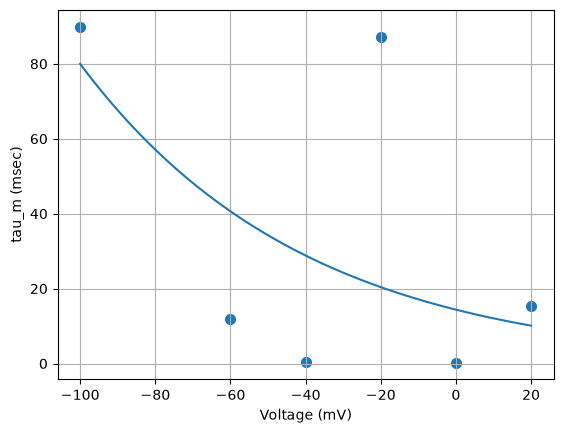

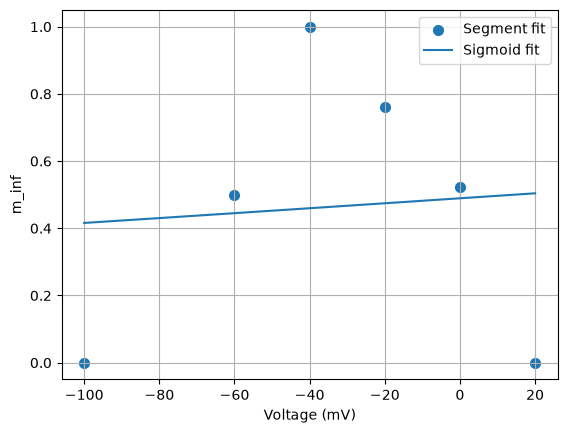

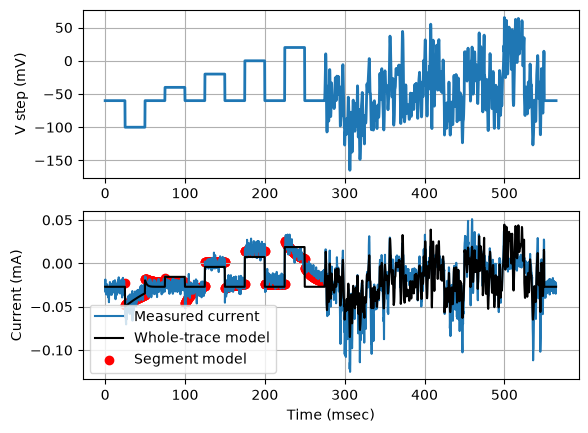

In [19]:
# %% SECTION 4: Function calls
if __name__ == "__main__":
    # Replace this with the path to the folder where provided input .txt file is!
    folder = "data"

    # Run function on the voltage-clamp data
    i = run_vclamp_model(folder)